In [ ]:
import numpy as np

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [ ]:
digits = load_digits()

X = digits.data
y = digits.target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1797, 64)
y shape: (1797,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [ ]:
baseline_model = RandomForestClassifier(
    n_estimators=50,
    random_state=42
)

In [ ]:
baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

In [ ]:
print("Baseline test accuracy:", baseline_accuracy)

Baseline test accuracy: 0.9592592592592593


In [ ]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)



baseline_cv_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=kf,
    scoring="accuracy"
)

print("Baseline fold accuracies:", baseline_cv_scores)
print("Baseline mean CV accuracy:", baseline_cv_scores.mean())

Baseline fold accuracies: [0.98412698 0.97222222 0.97211155 0.97609562 0.9561753 ]
Baseline mean CV accuracy: 0.9721463352937457


In [ ]:
grid_parameters = {
    "n_estimators": [50, 100],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}


rf_model = RandomForestClassifier(
    random_state=42
)

In [ ]:
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=grid_parameters,
    cv=kf,
    scoring="accuracy",
    refit=True
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [None, 10, 20],
                         'min_samples_split': [2, 5],
                         'n_estimators': [50, 100]},
             scoring='accuracy')

In [ ]:
print("Best Grid Search Paramters:")
print(grid_search.best_params_)

Best Grid Search Paramters:
{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}


In [ ]:
print("Best Grid Search CV accuracy:")
print(grid_search.best_score_)

Best Grid Search CV accuracy:
0.9753304243344084


In [ ]:
best_grid_model = grid_search.best_estimator_

In [ ]:
grid_pred = best_grid_model.predict(X_test)

grid_test_accuracy = accuracy_score(
    y_test,
    grid_pred
)

print("Grid Search test accuracy:", grid_test_accuracy)

Grid Search test accuracy: 0.9611111111111111


In [ ]:
random_parameters = {
    "n_estimators": [25, 50, 75, 100, 150, 200],
    "max_depth": [None, 5, 10, 15, 20, 25],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

In [ ]:
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=random_parameters,
    n_iter=8,
    cv=kf,
    scoring="accuracy",
    random_state=42,
    refit=True
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=RandomForestClassifier(random_state=42), n_iter=8,
                   param_distributions={'max_depth': [None, 5, 10, 15, 20, 25],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [25, 50, 75, 100, 150,
                                                         200]},
                   random_state=42, scoring='accuracy')

In [ ]:
print("Best Randomized Search parameters:")
print(random_search.best_params_)

print("Best Randomized Search CV accuracy:")
print(random_search.best_score_)

Best Randomized Search parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}
Best Randomized Search CV accuracy:
0.9753304243344084


In [ ]:
best_random_model = random_search.best_estimator_

In [ ]:
random_pred = best_random_model.predict(X_test)

random_test_accuracy = accuracy_score(
    y_test,
    random_pred
)

print("Randomized Search test accuracy:", random_test_accuracy)

Randomized Search test accuracy: 0.9611111111111111


In [ ]:
import pandas as pd


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving AirPassengers.csv to AirPassengers (1).csv


In [ ]:
df = pd.read_csv('AirPassengers.csv')

In [ ]:
print (df.head())

     Month  #Passengers
0  1949-01          112
1  1949-02          118
2  1949-03          132
3  1949-04          129
4  1949-05          121


In [ ]:
print(df.shape)

(144, 2)


In [ ]:
df['Month'] = pd.to_datetime(df['Month'])

df = df.set_index('Month')

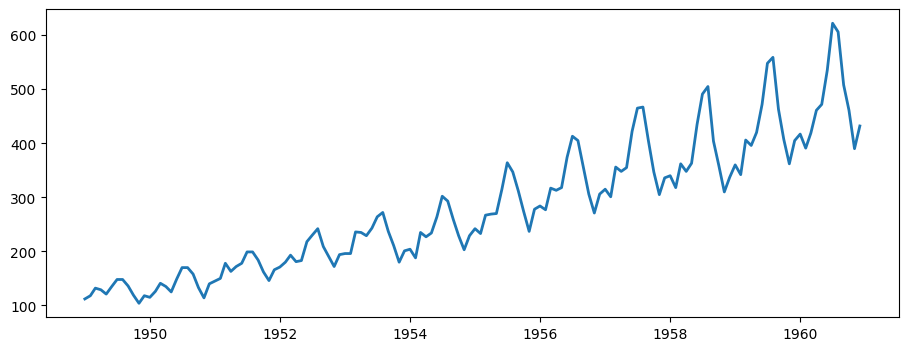

In [ ]:

import matplotlib.pyplot as plt
plt.figure(figsize=(11, 4))
# plt.plot(series.index, series)
plt.plot(df.index, df["#Passengers"], linewidth=2)

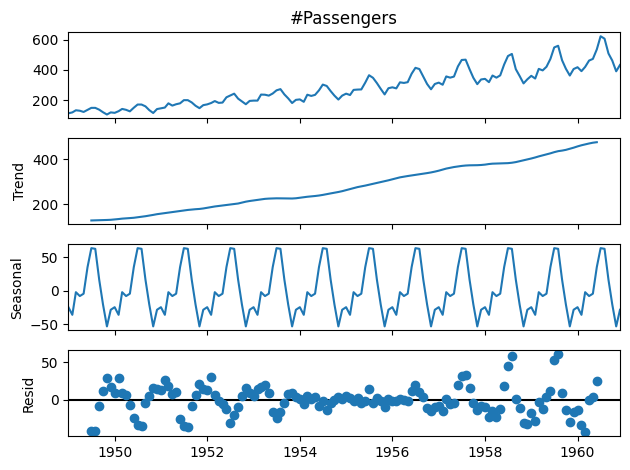

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(
  df["#Passengers"]
)

result.plot();